In [21]:
import pennylane as qml
from pennylane import numpy as np
import itertools

In [22]:
# Define Knapsack problem
weights = [3, 4, 5, 2, 3]
values = [8, 10, 12, 5, 7]
capacity = 10

slack_weights = [1, 2, 4, 8]

# Combine vectors
a = np.array(weights + slack_weights)
v = np.array(values + [0, 0, 0, 0])

n = len(a) # 9 qubits
lam = 50 # penalty coefficient

# Hamiltonian

$$
H = cI + \sum_{i} h_{i} Z_{i} + \sum_{i<j} J_{ij} Z_{i} Z_{j}
$$

with

$$
h_{i} = \frac{v_{i}}{2} - 6 \lambda a_{i}, \quad J_{ij} = \frac{\lambda a_{i} a_{j}}{2}, \quad c = 3629
$$

In [23]:
# Hamiltonian construction
h = v / 2 - 6 * lam * a

J = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        J[i, j] = lam * a[i] * a[j] / 2

c = -np.sum(v) / 2 + lam * (36 + np.sum(a**2) / 4)

coeffs = []
operators = []

# Local fields: h_i Z_i
for i in range(n):
    coeffs.append(float(h[i]))
    operators.append(qml.Z(i))

# Couplings: J_ij Z_i Z_j
for i in range(n):
    for j in range(i + 1, n):
        coeffs.append(float(J[i, j]))
        operators.append(qml.Z(i) @ qml.Z(j))

H = qml.dot(coeffs, operators)

print("Constant: ", c)
print("Hamiltonian: ", H)

Constant:  3629.0
Hamiltonian:  -896.0 * Z(0) + -1195.0 * Z(1) + -1494.0 * Z(2) + -597.5 * Z(3) + -896.5 * Z(4) + -300.0 * Z(5) + -600.0 * Z(6) + -1200.0 * Z(7) + -2400.0 * Z(8) + 300.0 * (Z(0) @ Z(1)) + 375.0 * (Z(0) @ Z(2)) + 150.0 * (Z(0) @ Z(3)) + 225.0 * (Z(0) @ Z(4)) + 75.0 * (Z(0) @ Z(5)) + 150.0 * (Z(0) @ Z(6)) + 300.0 * (Z(0) @ Z(7)) + 600.0 * (Z(0) @ Z(8)) + 500.0 * (Z(1) @ Z(2)) + 200.0 * (Z(1) @ Z(3)) + 300.0 * (Z(1) @ Z(4)) + 100.0 * (Z(1) @ Z(5)) + 200.0 * (Z(1) @ Z(6)) + 400.0 * (Z(1) @ Z(7)) + 800.0 * (Z(1) @ Z(8)) + 250.0 * (Z(2) @ Z(3)) + 375.0 * (Z(2) @ Z(4)) + 125.0 * (Z(2) @ Z(5)) + 250.0 * (Z(2) @ Z(6)) + 500.0 * (Z(2) @ Z(7)) + 1000.0 * (Z(2) @ Z(8)) + 150.0 * (Z(3) @ Z(4)) + 50.0 * (Z(3) @ Z(5)) + 100.0 * (Z(3) @ Z(6)) + 200.0 * (Z(3) @ Z(7)) + 400.0 * (Z(3) @ Z(8)) + 75.0 * (Z(4) @ Z(5)) + 150.0 * (Z(4) @ Z(6)) + 300.0 * (Z(4) @ Z(7)) + 600.0 * (Z(4) @ Z(8)) + 50.0 * (Z(5) @ Z(6)) + 100.0 * (Z(5) @ Z(7)) + 200.0 * (Z(5) @ Z(8)) + 200.0 * (Z(6) @ Z(7)) + 400.0 *

In [24]:
# QAOA circuit

# Scale the Hamiltonian for numerical convenience
scale = 1000.0

H_cost = qml.dot(
    [coef / scale for coef in coeffs],
    operators
)

H_mixer = qml.qaoa.mixers.x_mixer(range(n))

p = 2 # QAOA depth

dev = qml.device("default.qubit", wires=n)

def qaoa_circuit(params):
    # prepare |+>
    for i in range(n):
        qml.Hadamard(wires=i)

    # alternating cost and mixer Hamiltonians
    for layer in range(p):
        gamma = params[0, layer]
        beta = params[1, layer]

        qml.qaoa.cost_layer(gamma, H_cost)
        qml.qaoa.mixer_layer(beta, H_mixer)

@qml.qnode(dev, interface="autograd")
def cost_function(params):
    qaoa_circuit(params)
    return qml.expval(H_cost)

@qml.qnode(dev)
def probability_circuit(params):
    qaoa_circuit(params)
    return qml.probs(wires=range(n))

In [25]:
# optimize parameters
import numpy as onp

# initialize params
rng = onp.random.default_rng(42)

params = np.array(
    rng.uniform(0, 2*np.pi, size=(2, p)),
    requires_grad=True
)

optimizer = qml.AdamOptimizer(stepsize=0.05)

energies = []

for step in range(150):
    params = optimizer.step(cost_function, params)

    energy = float(cost_function(params))
    energies.append(energy)

    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy:.6f}")

print("Optimized parameters:")
print(params)

Step 0: Energy = 0.497087
Step 10: Energy = -0.478415
Step 20: Energy = -0.561168
Step 30: Energy = -0.638207
Step 40: Energy = -0.675797
Step 50: Energy = -0.683350
Step 60: Energy = -0.683832
Step 70: Energy = -0.684419
Step 80: Energy = -0.684647
Step 90: Energy = -0.684616
Step 100: Energy = -0.684630
Step 110: Energy = -0.684664
Step 120: Energy = -0.684662
Step 130: Energy = -0.684667
Step 140: Energy = -0.684667
Optimized parameters:
[[5.17476085 3.11598113]
 [5.84651938 3.74987827]]


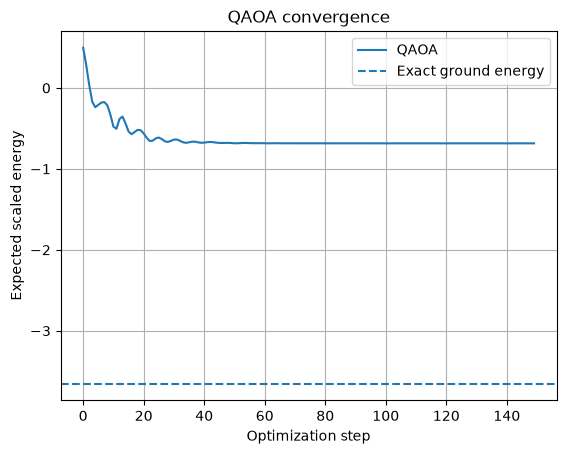

In [26]:
# Plot
import matplotlib.pyplot as plt

plt.plot(energies, label="QAOA")
plt.axhline(
    y=(-25 - c) / scale,
    linestyle="--",
    label="Exact ground energy"
)

plt.xlabel("Optimization step")
plt.ylabel("Expected scaled energy")
plt.title("QAOA convergence")
plt.legend()
plt.grid()
plt.show()

In [27]:
# Extract the most probable solution

probs = onp.asarray(probability_circuit(params))

# most probable computational basis states
top_indices = onp.argsort(probs)[::-1][:10]

for index in top_indices:
    bits = tuple(int(b) for b in format(index, f"0{n}b"))

    x = bits[:5]
    slack_bits = bits[5:]

    weight = sum(weights[i] * x[i] for i in range(5))
    value = sum(values[i] * x[i] for i in range(5))
    slack = sum(slack_weights[i] * slack_bits[i] for i in range(4))

    feasible = weight <= capacity

    print(
        f"Bits: {bits} | "
        f"P = {probs[index]:.4f} | "
        f"Value = {value} | "
        f"Weight = {weight} | "
        f"Slack = {slack} | "
        f"Feasible = {feasible}"
    )

Bits: (1, 0, 1, 0, 1, 1, 0, 0, 0) | P = 0.0218 | Value = 27 | Weight = 11 | Slack = 1 | Feasible = False
Bits: (1, 0, 1, 0, 1, 0, 0, 0, 0) | P = 0.0207 | Value = 27 | Weight = 11 | Slack = 0 | Feasible = False
Bits: (1, 1, 1, 0, 0, 0, 0, 1, 0) | P = 0.0164 | Value = 30 | Weight = 12 | Slack = 4 | Feasible = False
Bits: (0, 1, 1, 0, 1, 0, 0, 1, 0) | P = 0.0162 | Value = 29 | Weight = 12 | Slack = 4 | Feasible = False
Bits: (1, 1, 1, 0, 1, 1, 0, 0, 0) | P = 0.0127 | Value = 37 | Weight = 15 | Slack = 1 | Feasible = False
Bits: (1, 0, 1, 0, 1, 1, 0, 1, 0) | P = 0.0122 | Value = 27 | Weight = 11 | Slack = 5 | Feasible = False
Bits: (0, 1, 0, 1, 0, 0, 1, 1, 0) | P = 0.0106 | Value = 15 | Weight = 6 | Slack = 6 | Feasible = True
Bits: (1, 1, 1, 1, 1, 1, 1, 1, 0) | P = 0.0101 | Value = 42 | Weight = 17 | Slack = 7 | Feasible = False
Bits: (0, 1, 0, 1, 0, 1, 1, 1, 0) | P = 0.0099 | Value = 15 | Weight = 6 | Slack = 7 | Feasible = True
Bits: (0, 1, 1, 1, 0, 1, 1, 1, 0) | P = 0.0097 | Value = 27